In [32]:
import os, json
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import norm
from scipy.stats import zscore
from src import Questions
import matplotlib.patches as mpatches


plt.rcParams.update({'font.size': 17})

In [ ]:
# creating a dataframe of all of the annotator profiles
EXCLUDED_SCORES = ["2_13", "23_", "24_", "25_", "27_"]
questions = Questions().get_questions()
SCORED_ANNOTATOR_DIR = "annotation_artefacts/final_annotator_objects"
os.makedirs(SCORED_ANNOTATOR_DIR, exist_ok=True)

In [62]:
# making a raw scores (both characteristic and downstream) for each annotator
all_tasktype_df_by_model = {}
all_models = [
    "gpt_4o",
    "llama31_70B_Inst",
    "Qwen25_72B_Inst",
    "llama31_8B_Inst",
    "Qwen25_7B_Inst",
    "llama32_1B_Inst",
    "Qwen25_1dot5B_Inst"
]
for presented_model in all_models:
    all_tasktype_df = {}
    task_types = ['mt_and_summarization', 'syntaxes', 'knowledge_and_reasoning', 'semantics', 'qa_extraction']
    for tt in task_types:
        downstream_score_df = []
        for annfilename in os.listdir(SCORED_ANNOTATOR_DIR):
            annotator_filepath = os.path.join(SCORED_ANNOTATOR_DIR, annfilename)
            with open(annotator_filepath, "r") as  ao:
                annotator_object = json.load(ao)
            
            downstream_scores = {}
            for question_key, values in annotator_object["answers"].items():
                if values["answer"] == None or questions[question_key]["question_type"] != tt:
                    continue
                for qid, score_s in values["downstream_scores"][presented_model].items():
                    postfix = questions[question_key]["metrics"][0] # first metric entry is by convention default
                    matching_keys = [k for k in score_s if k.endswith(f"{postfix}_score")]
                    if not matching_keys:
                        raise ValueError(f"No key ends with '{postfix}' for qid {qid}")
                    correct_key = matching_keys[0]
                    downstream_scores[f"{qid}-sentence_type"] = values["sentence_type"]
                    downstream_scores[f"{qid}-sentence_length"] = values["sentence_length"]
                    downstream_scores[f"{qid}-sentence_grammaticality"] = values["grammaticality"]
                    downstream_scores[correct_key] = score_s[correct_key]

            downstream_score_df.append({
                "id" : annotator_object["id"],
                **downstream_scores,
            })
        all_tasktype_df[tt] = pd.DataFrame(downstream_score_df)
    all_tasktype_df_by_model[presented_model] = all_tasktype_df
    

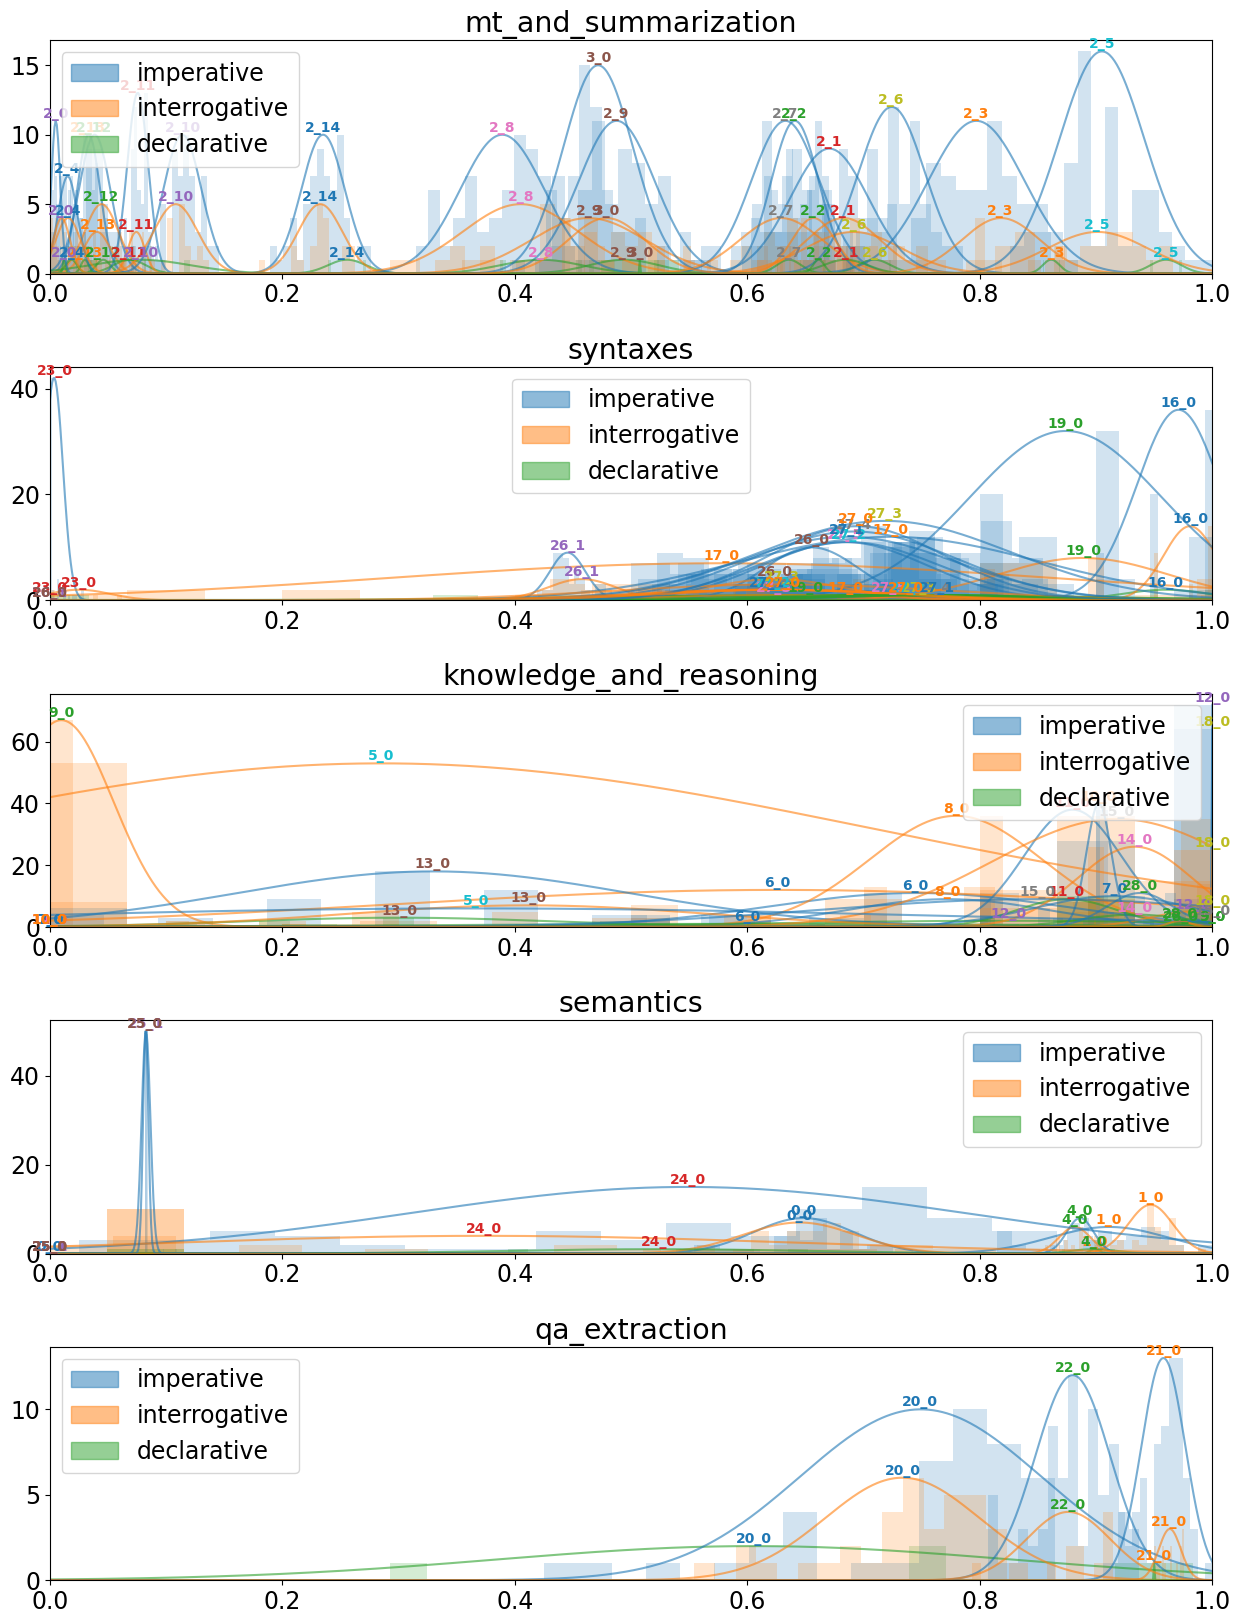

In [35]:
def collect_all_numbers(d):
    all_nums = []
    def recurse(x):
        if isinstance(x, dict):
            for v in x.values():
                recurse(v)
        elif isinstance(x, list):
            all_nums.extend(x)
    recurse(d)
    return all_nums

def normalize_nested_dict(d, min_val, max_val):
    def recurse(x):
        if isinstance(x, dict):
            for k, v in x.items():
                x[k] = recurse(v)
        elif isinstance(x, list):
            return [(i - min_val) / (max_val - min_val) if max_val != min_val else 0 for i in x]
        return x
    return recurse(d)

def remove_outliers(list_of_values):
    q1 = np.percentile(list_of_values, 25)
    q3 = np.percentile(list_of_values, 75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    filtered_data = [x for x in list_of_values if lower_bound <= x <= upper_bound]
    return filtered_data

# propmt_sentence_type
characteristics_column = 0
task_group_histogram_data = {}
for tt in task_types:
    taskdf = all_tasktype_df[tt].drop(columns=['id'])
    cols = list(taskdf.columns)
    
    group_tasks_histogram_data = {}
    for i in range(0, len(cols), 4):
        chunk = cols[i:i+4]
        label_scores = {}
        for group_name, group_df in taskdf.groupby(chunk[characteristics_column]):
            label_scores[group_name] = group_df[chunk[-1]].tolist()
        
        task_code = chunk[0].split("-")[0]
        group_tasks_histogram_data[task_code] = label_scores

    all_nums = collect_all_numbers(group_tasks_histogram_data)
    min_val = min(all_nums)
    max_val = max(all_nums)
    task_group_histogram_data[tt] = normalize_nested_dict(group_tasks_histogram_data, min_val, max_val)

# print(json.dumps(task_group_histogram_data, indent=4))
# Plot all as overlapping histograms
colors = {
    "imperative" : '#1f77b4',
    "interrogative" : '#ff7f0e',
    "declarative" : '#2ca02c',
}

fig, axes = plt.subplots(len(all_tasktype_df.keys()), 1, figsize=(15, 4 * len(all_tasktype_df.keys())))
plt.subplots_adjust(hspace=0.4)  # Increase for more gap
# fig.xlim(0, 1)

for ax, (group_name, group_hist_data) in zip(axes, task_group_histogram_data.items()):
    ax.set_xlim(0, 1)
    ax.set_title(group_name)
    
    qdi_list = list(group_hist_data.keys())
    colors_by_qdi = {qdi: plt.cm.tab10(i % 10) for i, qdi in enumerate(qdi_list)}
    for qdi, classifications in group_hist_data.items():
        for label, score_list in classifications.items():
            score_list = remove_outliers(score_list)
            counts, bin_edges, _ = ax.hist(score_list, bins=15, alpha=0.2, label=f'Data {i}', color=colors[label])
            mu, std = np.mean(score_list), np.std(score_list)
            if std == 0:
                std = 1e-6
            x = np.linspace(0, 1, 1000)
            p = norm.pdf(x, mu, std)
            p_max = np.max(p)
            
            if p_max == 0:
                scale = 1  # or skip plotting the curve
            else:
                scale = max(counts) / p_max

            # Get the current color used for the histogram
            ax.plot(x, p * scale, color=colors[label], alpha=0.6)

            peak_x = x[np.argmax(p)]
            peak_y = max(p) * scale
            ax.text(peak_x, peak_y, qdi, color=colors_by_qdi[qdi], ha='center', va='bottom', fontsize=10, fontweight='bold')

            legend_patches = [mpatches.Patch(color=col, label=label, alpha=0.5) for label, col in colors.items()]
            ax.legend(handles=legend_patches)
    # break


In [36]:
all_tasktype_df["mt_and_summarization"]

,id,2_14-sentence_type,2_14-sentence_length,2_14-sentence_grammaticality,Machine Translation-hau_Latn-2_14-bleu_score,2_13-sentence_type,2_13-sentence_length,2_13-sentence_grammaticality,Machine Translation-amh_Ethi-2_13-bleu_score,2_12-sentence_type,...,2_1-sentence_grammaticality,Machine Translation-rus_Cyrl-2_1-bleu_score,2_0-sentence_type,2_0-sentence_length,2_0-sentence_grammaticality,Machine Translation-zho_Hans-2_0-bleu_score,3_0-sentence_type,3_0-sentence_length,3_0-sentence_grammaticality,Dialogue Summarization-3_0-rouge_score
0,34,imperative,4.0,correct,10.128283,imperative,4.0,correct,0.724865,imperative,...,correct,28.635613,imperative,4.0,correct,0.149518,imperative,4.0,correct,27.959649
1,63,imperative,5.0,correct,8.461064,imperative,5.0,correct,0.717026,imperative,...,correct,28.996907,imperative,5.0,correct,0.203375,imperative,3.0,correct,19.175207
2,75,imperative,5.0,correct,10.543812,imperative,5.0,correct,0.547400,imperative,...,correct,28.267476,imperative,5.0,correct,0.215169,imperative,10.0,correct,19.034314
3,22,interrogative,9.0,correct,3.144250,interrogative,9.0,correct,2.678064,interrogative,...,correct,27.128036,interrogative,9.0,correct,0.268655,interrogative,10.0,correct,20.949323
4,59,interrogative,4.0,correct,9.941594,interrogative,4.0,correct,0.985786,interrogative,...,correct,28.023221,interrogative,4.0,correct,0.287299,interrogative,3.0,correct,18.648041
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
94,37,imperative,4.0,correct,9.599326,imperative,4.0,correct,1.446367,imperative,...,correct,28.245878,imperative,4.0,correct,0.085285,imperative,9.0,correct,20.968123
95,60,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,imperative,3.0,correct,19.467614
96,76,imperative,2.0,correct,8.720605,imperative,2.0,correct,1.190329,imperative,...,correct,28.286357,imperative,2.0,correct,0.187701,imperative,14.0,correct,29.200810
97,99,imperative,10.0,correct,9.151800,imperative,10.0,correct,1.406482,imperative,...,correct,30.286805,imperative,10.0,correct,0.166158,imperative,11.0,correct,18.027537


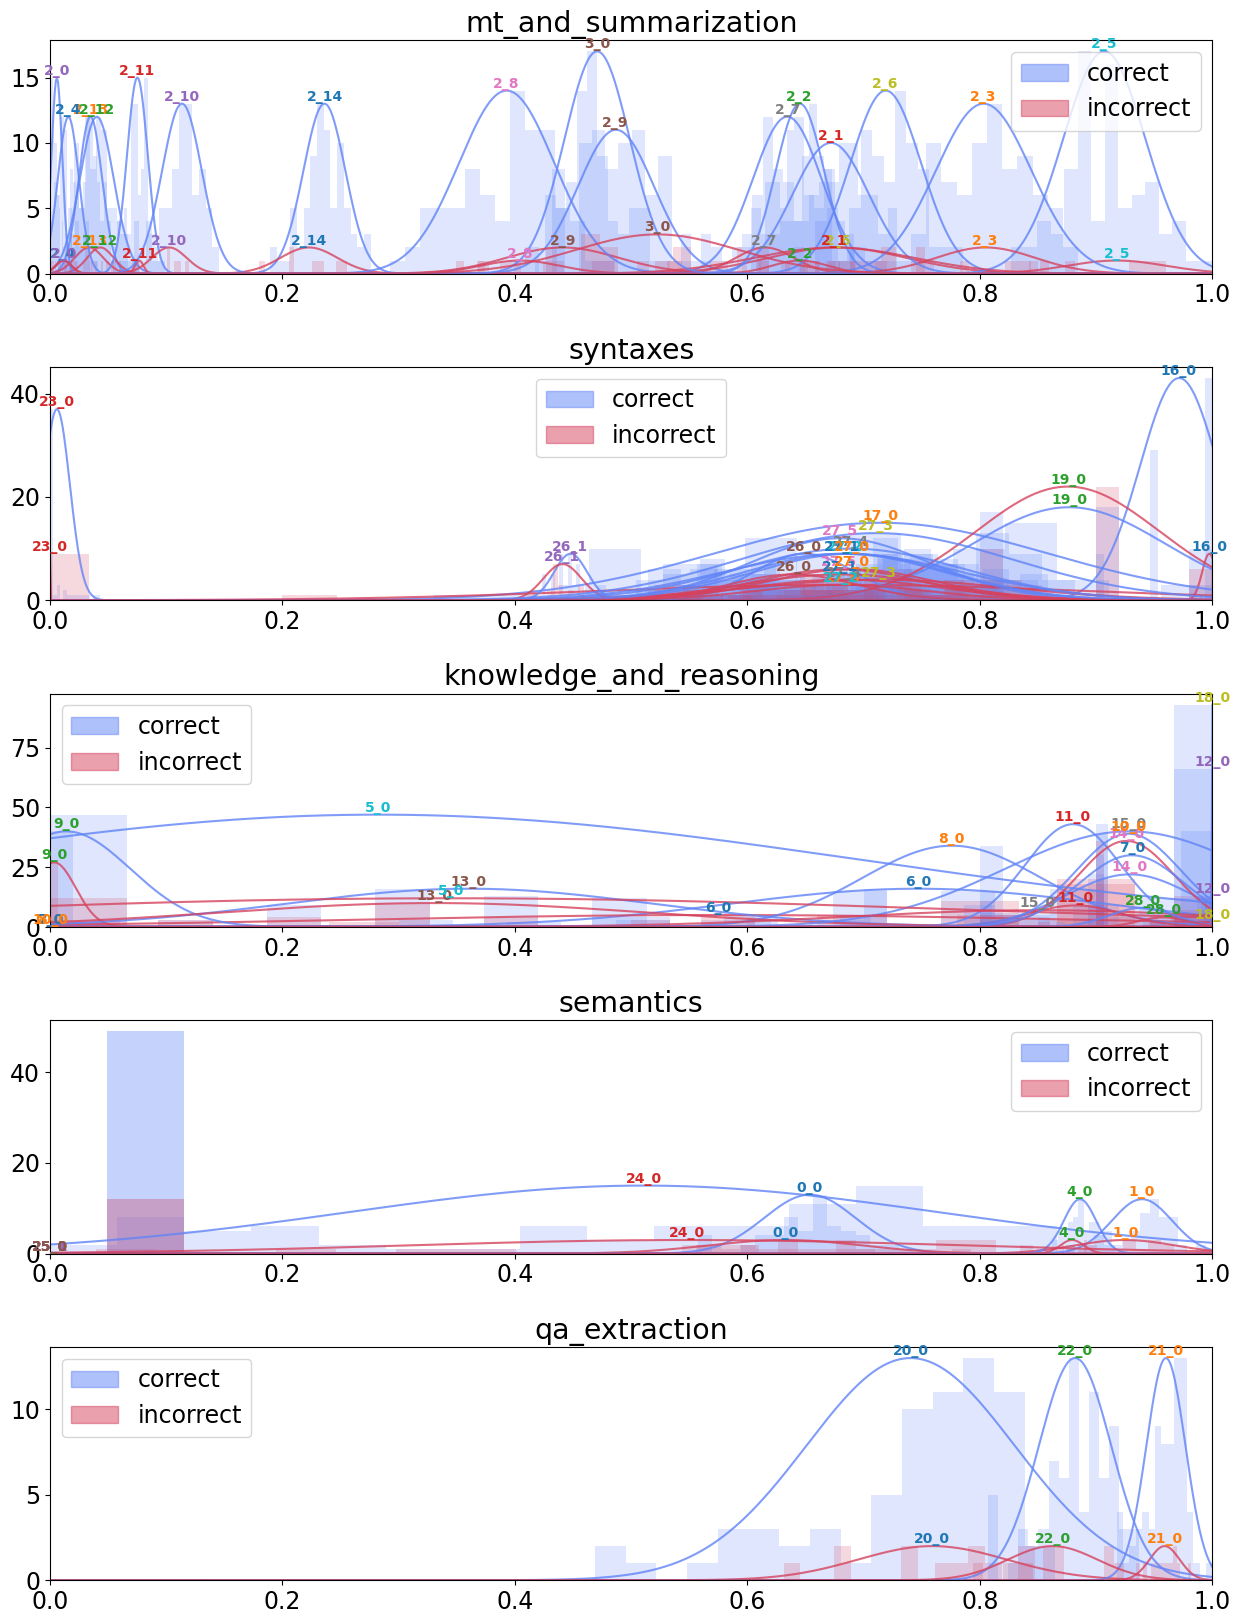

In [37]:
# propmt_sentence_type
characteristics_column = 2
task_group_histogram_data = {}
for tt in task_types:
    taskdf = all_tasktype_df[tt].drop(columns=['id'])
    cols = list(taskdf.columns)
    
    group_tasks_histogram_data = {}
    for i in range(0, len(cols), 4):
        chunk = cols[i:i+4]
        label_scores = {}
        for group_name, group_df in taskdf.groupby(chunk[characteristics_column]):
            label_scores[group_name] = group_df[chunk[-1]].tolist()
        
        task_code = chunk[0].split("-")[0]
        group_tasks_histogram_data[task_code] = label_scores

    all_nums = collect_all_numbers(group_tasks_histogram_data)
    min_val = min(all_nums)
    max_val = max(all_nums)
    task_group_histogram_data[tt] = normalize_nested_dict(group_tasks_histogram_data, min_val, max_val)

# print(json.dumps(task_group_histogram_data, indent=4))
# Plot all as overlapping histograms
colors = {
    "correct" : '#6084f7',
    "incorrect" : '#d6425d',
}

fig, axes = plt.subplots(len(all_tasktype_df.keys()), 1, figsize=(15, 4 * len(all_tasktype_df.keys())))
plt.subplots_adjust(hspace=0.4)  # Increase for more gap
# fig.xlim(0, 1)

for ax, (group_name, group_hist_data) in zip(axes, task_group_histogram_data.items()):
    ax.set_xlim(0, 1)
    ax.set_title(group_name)
    
    qdi_list = list(group_hist_data.keys())
    colors_by_qdi = {qdi: plt.cm.tab10(i % 10) for i, qdi in enumerate(qdi_list)}
    for qdi, classifications in group_hist_data.items():
        for label, score_list in classifications.items():
            score_list = remove_outliers(score_list)
            counts, bin_edges, _ = ax.hist(score_list, bins=15, alpha=0.2, label=f'Data {i}', color=colors[label])
            mu, std = np.mean(score_list), np.std(score_list)
            if std == 0:
                std = 1e-6
            x = np.linspace(0, 1, 1000)
            p = norm.pdf(x, mu, std)
            p_max = np.max(p)
            
            if p_max == 0:
                scale = 1  # or skip plotting the curve
            else:
                scale = max(counts) / p_max

            # Get the current color used for the histogram
            ax.plot(x, p * scale, color=colors[label], alpha=0.8)

            peak_x = x[np.argmax(p)]
            peak_y = max(p) * scale
            ax.text(peak_x, peak_y, qdi, color=colors_by_qdi[qdi], ha='center', va='bottom', fontsize=10, fontweight='bold')

            legend_patches = [mpatches.Patch(color=col, label=label, alpha=0.5) for label, col in colors.items()]
            ax.legend(handles=legend_patches)
    # break


In [38]:
# propmt_sentence_type
characteristics_column = 1
tg_correlation_df = []
for tt in task_types:
    taskdf = all_tasktype_df[tt].drop(columns=['id'])
    cols = list(taskdf.columns)

    tg_correlation_data = []
    for i in range(0, len(cols), 4):
        chunk = cols[i:i+4]
        
        correlation = taskdf[chunk[characteristics_column]].corr(taskdf[chunk[-1]])
        task_name = "-".join(chunk[-1].split("-")[:-2])
        tg_correlation_data.append(correlation)

    tg_correlation_data = [abs(val) for val in tg_correlation_data]
    tg_correlation_df.append({
        "Task Group": tt,
        "Corr. Avg": format(round(np.mean(tg_correlation_data), 2), ".2f"),
        "Corr. Std": format(round(np.std(tg_correlation_data), 2), ".2f"),
    })
# print(tg_correlation_df)
tg_correlation_df = pd.DataFrame(tg_correlation_df)
tg_correlation_df

,Task Group,Corr. Avg,Corr. Std
0,mt_and_summarization,0.18,0.13
1,syntaxes,0.39,0.23
2,knowledge_and_reasoning,0.16,0.10
3,semantics,0.25,0.15
4,qa_extraction,0.16,0.14


In [39]:
print(tg_correlation_df.replace('_', r'\\_', regex=True).to_latex(index=False))

\begin{tabular}{lll}
\toprule
Task Group & Corr. Avg & Corr. Std \\
\midrule
mt\_and\_summarization & 0.18 & 0.13 \\
syntaxes & 0.39 & 0.23 \\
knowledge\_and\_reasoning & 0.16 & 0.10 \\
semantics & 0.25 & 0.15 \\
qa\_extraction & 0.16 & 0.14 \\
\bottomrule
\end{tabular}



In [40]:
all_tasktype_df['knowledge_and_reasoning']

,id,6_0-sentence_type,6_0-sentence_length,6_0-sentence_grammaticality,Free Generation: G30SPKI-6_0-llm_judge_score,8_0-sentence_type,8_0-sentence_length,8_0-sentence_grammaticality,Free Generation: Adhan-8_0-llm_judge_score,9_0-sentence_type,...,7_0-sentence_grammaticality,Free Generation: Hijrah-7_0-llm_judge_score,10_0-sentence_type,10_0-sentence_length,10_0-sentence_grammaticality,Free Generation: Giant Drum-10_0-llm_judge_drum_score,28_0-sentence_type,28_0-sentence_length,28_0-sentence_grammaticality,Linguistically-conditioned Text Generation-28_0-requirement_checker_score
0,34,interrogative,13.0,incorrect,0.0,interrogative,15.0,correct,0.9,interrogative,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,63,imperative,14.0,correct,0.9,NaN,NaN,NaN,NaN,interrogative,...,correct,1.0,imperative,14.0,incorrect,0.9,imperative,8.0,correct,0.9375
2,75,imperative,23.0,correct,0.7,interrogative,12.0,correct,0.8,interrogative,...,incorrect,0.9,imperative,16.0,correct,0.9,imperative,10.0,correct,0.9300
3,22,imperative,17.0,correct,0.7,imperative,10.0,correct,0.8,interrogative,...,correct,0.9,imperative,20.0,correct,0.9,interrogative,23.0,correct,0.9700
4,59,interrogative,17.0,correct,0.7,interrogative,7.0,correct,0.8,interrogative,...,incorrect,0.9,interrogative,19.0,correct,0.9,interrogative,9.0,incorrect,0.9825
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
94,37,imperative,14.0,correct,0.8,interrogative,30.0,incorrect,0.8,interrogative,...,correct,0.8,imperative,27.0,correct,0.9,imperative,10.0,incorrect,0.9575
95,60,interrogative,10.0,correct,0.0,interrogative,11.0,correct,0.6,interrogative,...,NaN,NaN,imperative,16.0,correct,0.9,NaN,NaN,NaN,NaN
96,76,NaN,NaN,NaN,NaN,interrogative,16.0,incorrect,0.6,interrogative,...,correct,0.9,declarative,48.0,correct,0.9,imperative,6.0,incorrect,0.9275
97,99,interrogative,23.0,correct,0.8,imperative,18.0,correct,0.7,interrogative,...,NaN,NaN,imperative,57.0,correct,0.9,declarative,32.0,correct,0.9800


In [67]:
# propmt LENGTH
CHAR_COLUMN = 1
presented_model = ["gpt_4o", "Qwen25_72B_Inst", "llama31_70B_Inst"]
task_corrdf_by_model = {}
for mmm in presented_model:
    task_correlation_df = []
    for tt in task_types:
        taskdf = all_tasktype_df_by_model[mmm][tt].drop(columns=['id'])
        cols = list(taskdf.columns)
        for i in range(0, len(cols), 4):
            chunk = cols[i:i+4]
            task_qidx = chunk[-1].split("-")[-2]
            if not any(task_qidx.startswith(prefix) for prefix in EXCLUDED_SCORES):
                correlation = taskdf[chunk[CHAR_COLUMN]].corr(taskdf[chunk[-1]])
                task_name = "-".join(chunk[-1].split("-")[:-2]).replace("grammatical_classification_","")
                task_correlation_df.append({
                    "Task Name" : task_name,
                    f"Corr. {mmm.split("_")[0]}" : correlation,
                })
    task_correlation_df = pd.DataFrame(task_correlation_df)
    task_corrdf_by_model[mmm] = task_correlation_df

In [68]:
from functools import reduce
dfs = list(task_corrdf_by_model.values())
merged_df = reduce(lambda left, right: pd.merge(left, right, on="Task Name", how="outer"), dfs)
merged_df

,Task Name,Corr. gpt,Corr. Qwen25,Corr. llama31
0,Dialogue Summarization,0.453622,0.424689,0.463132
1,Extractive QA,-0.212764,0.014741,0.036289
2,Free Generation: Adhan,0.079844,0.207157,-0.099070
3,Free Generation: Arithmetic,0.049907,0.019219,-0.117124
4,Free Generation: Balonku Song,-0.017427,0.155739,0.167195
5,Free Generation: G30SPKI,0.101820,0.039983,0.124039
6,Free Generation: Giant Drum,-0.370671,-0.597074,-0.399808
7,Free Generation: Grammar Correction I,0.028412,0.076409,0.045942
8,Free Generation: Grammar Correction II,-0.128761,-0.049006,-0.115930
9,Free Generation: Hijrah,0.042507,-0.091950,0.085159


In [69]:
merged_df = merged_df.applymap(
    lambda x: f"{x:.2f}".replace('.', ',') if isinstance(x, float)
    else x.replace('_', r'\_') if isinstance(x, str)
    else x
)
print(merged_df.to_latex(index=False))

\begin{tabular}{llll}
\toprule
Task Name & Corr. gpt & Corr. Qwen25 & Corr. llama31 \\
\midrule
Dialogue Summarization & 0,45 & 0,42 & 0,46 \\
Extractive QA & -0,21 & 0,01 & 0,04 \\
Free Generation: Adhan & 0,08 & 0,21 & -0,10 \\
Free Generation: Arithmetic & 0,05 & 0,02 & -0,12 \\
Free Generation: Balonku Song & -0,02 & 0,16 & 0,17 \\
Free Generation: G30SPKI & 0,10 & 0,04 & 0,12 \\
Free Generation: Giant Drum & -0,37 & -0,60 & -0,40 \\
Free Generation: Grammar Correction I & 0,03 & 0,08 & 0,05 \\
Free Generation: Grammar Correction II & -0,13 & -0,05 & -0,12 \\
Free Generation: Hijrah & 0,04 & -0,09 & 0,09 \\
Free Generation: Hillary Clinton & -0,06 & -0,24 & -0,10 \\
Free Generation: Karak Kaliang & 0,32 & 0,62 & 0,29 \\
Free Generation: MBZUAI & 0,10 & -0,04 & 0,15 \\
Free Generation: Olympics Medallists & 0,21 & 0,14 & 0,02 \\
Free Generation: School Life & 0,06 & -0,04 & -0,02 \\
Free Generation: Scientific Letter & 0,06 & 0,13 & -0,17 \\
Free Generation: Shakespeare-Prompt Jailb

/var/folders/9t/9r8_fqln16b43khrkh9lb4kh0000gn/T/ipykernel_65843/3063130960.py:1: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  merged_df = merged_df.applymap(


In [102]:
# 0 for TONE, 2 for GRAMMAR
CHAR_COLUMN = 0
task_lingcat_scores_by_model = {}
for mmm in all_tasktype_df_by_model.keys():
    task_lingcat_scores_by_model[mmm] = {}
    for tt in task_types:
        task_lingcat_scores_by_model[mmm][tt] = {}
        taskdf = all_tasktype_df_by_model[mmm][tt].drop(columns=['id'])
        cols = list(taskdf.columns)
        for i in range(0, len(cols), 4):
            chunk = cols[i:i+4]
            task_qidx = chunk[-1].split("-")[-2]
            if not any(task_qidx.startswith(prefix) for prefix in EXCLUDED_SCORES):
                task_lingcat_scores_by_model[mmm][tt][task_qidx] = {}
                chunkdf = taskdf[chunk].dropna()
                for ptone, tone_group in chunkdf.groupby(chunk[CHAR_COLUMN]):
                    task_lingcat_scores_by_model[mmm][tt][task_qidx][ptone] = tone_group[chunk[-1]].to_list()

In [104]:
task_lingcat_scores_by_model

{'gpt_4o': {'mt_and_summarization': {'2_14': {'declarative': [17.927482034707896,
     22.14371713913576],
    'imperative': [17.570766107081315,
     20.14115959882314,
     19.109176253134315,
     19.874580447866407,
     17.981027520094646,
     18.982603175398484,
     18.588781100325814,
     19.25964078302245,
     17.390013941266304,
     18.39915482800868,
     18.60508544822784,
     18.493268237401477,
     16.575950124604898,
     18.441644111607975,
     17.11444192580151,
     16.986409262471216,
     18.05683605629756,
     17.572972126734047,
     19.63860714415886,
     19.004960754876603,
     18.363026958262225,
     19.3083068049401,
     18.4256186713562,
     18.061159236731918,
     18.13137986847244,
     17.520631893191837,
     18.957817580613284,
     20.72148270039705,
     17.61344897877526,
     19.5751325101401,
     19.547846365652564,
     20.244752726746285,
     17.405622692081916,
     20.301042603208288,
     17.67915092603933,
     18.4570368021922

In [116]:
REJECT_THRESHOLD = 0.05

from scipy.stats import ttest_ind
from itertools import combinations

def pairwise_p_values_with_higher(data_dict):
    results = {}
    for (key1, values1), (key2, values2) in combinations(data_dict.items(), 2):
        _, p = ttest_ind(values1, values2, equal_var=False)
        
        mean1 = sum(values1) / len(values1)
        mean2 = sum(values2) / len(values2)
        higher = key1 if mean1 > mean2 else key2

        results[f"{key1} ---- {key2}"] = {
            "p" : p,
            "higher" : higher,
        }
    return results




n_Ho_rejects_data = {}
for mmm in task_lingcat_scores_by_model.keys():
    n_Ho_rejects_data[mmm] = {}
    for tg in task_lingcat_scores_by_model[mmm].keys():
        n_Ho_rejects_data[mmm][tg] = {}
        for qidx in task_lingcat_scores_by_model[mmm][tg].keys():
            ttest_result = pairwise_p_values_with_higher(task_lingcat_scores_by_model[mmm][tg][qidx])
            for ttest_values in ttest_result.values():
                if ttest_values['p'] < REJECT_THRESHOLD:                    
                    if ttest_values['higher'] in n_Ho_rejects_data[mmm][tg]:
                        n_Ho_rejects_data[mmm][tg][ttest_values['higher']] += 1
                    else:
                        n_Ho_rejects_data[mmm][tg][ttest_values['higher']] = 1

In [118]:
n_Ho_rejects_data

{'gpt_4o': {'mt_and_summarization': {'imperative': 10,
   'declarative': 5,
   'interrogative': 1},
  'syntaxes': {},
  'knowledge_and_reasoning': {'declarative': 1,
   'interrogative': 2,
   'imperative': 1},
  'semantics': {'imperative': 1, 'interrogative': 1},
  'qa_extraction': {}},
 'llama31_70B_Inst': {'mt_and_summarization': {'imperative': 1,
   'declarative': 4,
   'interrogative': 1},
  'syntaxes': {'interrogative': 1},
  'knowledge_and_reasoning': {'interrogative': 2, 'declarative': 3},
  'semantics': {'interrogative': 2},
  'qa_extraction': {'interrogative': 1}},
 'Qwen25_72B_Inst': {'mt_and_summarization': {'imperative': 8,
   'interrogative': 1,
   'declarative': 1},
  'syntaxes': {'declarative': 1, 'interrogative': 1},
  'knowledge_and_reasoning': {'declarative': 3,
   'imperative': 4,
   'interrogative': 1},
  'semantics': {'imperative': 1},
  'qa_extraction': {}},
 'llama31_8B_Inst': {'mt_and_summarization': {'interrogative': 7,
   'declarative': 3},
  'syntaxes': {},
 

In [122]:
n_Ho_rejects_totalreject_df = []
n_Ho_rejects_which_df = []

for model in n_Ho_rejects_data:
    tg_values_total = {}
    tg_values_which = {}
    for tg, values in n_Ho_rejects_data[model].items():
        tg_values_total[tg] = sum(values.values())
        tg_values_which[tg] = max(values, key=values.get) if values else None

    n_Ho_rejects_totalreject_df.append({
        "Model" : model,
        **tg_values_total,
    })

    n_Ho_rejects_which_df.append({
        "Model" : model,
        **tg_values_which,
    })


In [123]:
pd.DataFrame(n_Ho_rejects_totalreject_df)

,Model,mt_and_summarization,syntaxes,knowledge_and_reasoning,semantics,qa_extraction
0,gpt_4o,16,0,4,2,0
1,llama31_70B_Inst,6,1,5,2,1
2,Qwen25_72B_Inst,10,2,8,1,0
3,llama31_8B_Inst,10,0,2,3,0
4,Qwen25_7B_Inst,10,2,0,1,2
5,llama32_1B_Inst,16,0,3,0,1
6,Qwen25_1dot5B_Inst,8,2,1,0,1


In [124]:
pd.DataFrame(n_Ho_rejects_which_df)

,Model,mt_and_summarization,syntaxes,knowledge_and_reasoning,semantics,qa_extraction
0,gpt_4o,imperative,None,interrogative,imperative,None
1,llama31_70B_Inst,declarative,interrogative,declarative,interrogative,interrogative
2,Qwen25_72B_Inst,imperative,declarative,imperative,imperative,None
3,llama31_8B_Inst,interrogative,None,interrogative,interrogative,None
4,Qwen25_7B_Inst,imperative,declarative,None,declarative,declarative
5,llama32_1B_Inst,interrogative,None,imperative,None,imperative
6,Qwen25_1dot5B_Inst,imperative,declarative,interrogative,None,imperative
